# Phase 2 — Regularization (10)

Issue #66, owned by affan80. Which regularization helps the tuned LSTM on FD001?

**Protocol.** Start from `configs/lstm.yaml`: one layer, 64 units, dropout 0.3,
window 30. Change one factor at a time; all other settings stay fixed. Use the
shared trainer (#53), the same three engine-grouped folds (seed 42), and an
inner holdout of 20% of each fold's training engines for early stopping.
Sensor selection and scaling fit on the fitting engines only. Training is on
CPU with one numerical thread and seed 42. Prediction always uses stride 1.

**Provisional selection rule.** #55 is still open. As in the merged LSTM study
(#58), train capped models at 125 and rank by mean fold RMSE on outer-held-out
cycles with true, uncapped RUL ≤ 130. Show uncapped training beside every capped
setting. Save every outer-held-out prediction so a revised selection threshold
can be applied later; a revised **training cap requires retraining**.

**Training engines only.** `load_training` opens only `train_FD001.txt`.
Neither official test cycles nor official RUL labels are opened or scored.
The official test runs once in #71. These are exploratory CV findings for the
model freeze, not an unbiased estimate of the selected setting's future error.


In [1]:
from pathlib import Path
import json
import hashlib

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Image, display

from rul.data.load import load_training
from rul.training.config import load_config
from rul.training.regularization import (
    FACTORS, plot_regularization, regularization_table, run_regularization,
)

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
METRICS, FIGURES = ROOT / "results/metrics", ROOT / "results/figures"
CACHE = ROOT / "results/models/studies/regularization"
torch.set_num_threads(1)
config = load_config(ROOT / "configs/regularization.yaml")
train = load_training(config["subset"], data_dir=ROOT / "data/raw/CMAPSSData")
print(f"{train['unit'].nunique()} training engines, {len(train):,} cycles; CPU, seed 42")
print("Baseline:", {k: config[k] for k in ("model", "inputs", "training", "selection", "target")})


100 training engines, 20,631 cycles; CPU, seed 42
Baseline: {'model': {'type': 'lstm', 'hidden_size': 64, 'num_layers': 1, 'dropout': 0.3}, 'inputs': {'type': 'windows', 'window': 30, 'stride': 1, 'n_regimes': 1, 'include_cycle': False}, 'training': {'epochs': 100, 'batch_size': 256, 'learning_rate': 0.001, 'weight_decay': 0.0, 'grad_clip': 1.0, 'scheduler': 'cosine', 'patience': 10, 'loss': 'mse', 'device': 'cpu', 'seed': 42, 'input_noise_std': 0.0}, 'selection': {'max_true_rul': 130}, 'target': {'cap': 125}}


## 1. One factor at a time

The baseline plus two alternatives for each of five factors gives **11 settings**.
Each runs with capped and uncapped training, each on three folds: **66 fits**.

| Factor | Baseline | Alternatives |
|---|---:|---|
| Output dropout (one-layer LSTM) | 0.3 | 0.1, 0.5 |
| Adam weight decay (L2) | 0 | 0.0001, 0.001 |
| Gaussian input-noise standard deviation | 0 | 0.01, 0.05 |
| Training-window stride | 1 | 2, 5 |
| Early-stopping patience | 10 | 5, 20 |

Noise is in fold-scaled sensor units, resampled for each training batch using a
dedicated seeded RNG. Validation and inference stay clean; source arrays are
unchanged. Stride reduces training windows and optimizer steps per epoch; it is
an end-to-end sampling/compute comparison, not an equal-update experiment.
The cosine schedule and maximum of 100 epochs stay fixed for all settings.

Per-run caches are gitignored. A cache is reused only when the data, source,
resolved config and runtime versions match and its prediction checksum passes.
Delete the cache to force retraining. The committed metrics and predictions
are the reviewable evidence; model checkpoints are unnecessary for this study.


In [2]:
records, predictions = run_regularization(train, config, CACHE)
table = regularization_table(records)


baseline, capped: 15.784 ± 0.440


baseline, uncapped: 30.794 ± 1.513


dropout_0.1, capped: 16.813 ± 0.418


dropout_0.1, uncapped: 32.430 ± 2.050


dropout_0.5, capped: 16.769 ± 1.053


dropout_0.5, uncapped: 30.835 ± 2.689


... (12 outputs left out)

patience_5, capped: 16.250 ± 0.920


patience_5, uncapped: 30.794 ± 1.513


patience_20, capped: 15.784 ± 0.440


patience_20, uncapped: 30.794 ± 1.513


## 2. Results table

Lower selection RMSE is better. “±” is the sample standard deviation across
the three folds, **not** uncertainty across training seeds or a confidence
interval. Delta compares each capped setting with the same baseline run.
Full-precision scores, all-cycle RMSE/MAE/NASA scores, epochs, timings, fold
membership and stage errors are retained in the exported CSV/JSON.


In [3]:
METRICS.mkdir(parents=True, exist_ok=True)
table.to_csv(METRICS / "fd001_regularization.csv", index=False)
shown = pd.DataFrame({
    "setting": table.variant,
    "capped selection RMSE": [f"{m:.2f} ± {s:.2f}" for m, s in zip(
        table.capped_selection_rmse, table.capped_selection_std)],
    "uncapped selection RMSE": [f"{m:.2f} ± {s:.2f}" for m, s in zip(
        table.uncapped_selection_rmse, table.uncapped_selection_std)],
    "capped delta": table.delta_from_baseline.round(3),
    "capped best epochs": table.capped_best_epochs,
    "capped fit minutes": (table.capped_seconds / 60).round(2),
})
display(shown)


,setting,capped selection RMSE,uncapped selection RMSE,capped delta,capped best epochs,capped fit minutes
0,baseline,15.78 ± 0.44,30.79 ± 1.51,0.000,"[11, 20, 20]",0.79
1,patience_20,15.78 ± 0.44,30.79 ± 1.51,0.000,"[11, 20, 20]",1.02
2,weight_decay_0.0001,15.83 ± 0.39,30.97 ± 3.21,0.048,"[11, 20, 24]",0.82
3,input_noise_std_0.01,15.87 ± 0.40,30.13 ± 1.11,0.085,"[11, 20, 20]",0.80
4,input_noise_std_0.05,16.04 ± 0.43,30.06 ± 1.64,0.259,"[11, 20, 20]",0.80
5,patience_5,16.25 ± 0.92,30.79 ± 1.51,0.466,"[11, 10, 13]",0.45
6,dropout_0.5,16.77 ± 1.05,30.84 ± 2.69,0.985,"[11, 25, 20]",0.80
7,dropout_0.1,16.81 ± 0.42,32.43 ± 2.05,1.029,"[11, 9, 20]",0.68
8,stride_2,17.47 ± 1.03,32.33 ± 3.98,1.691,"[7, 35, 28]",0.53
9,stride_5,17.52 ± 0.61,31.62 ± 2.44,1.736,"[15, 48, 51]",0.41


## 3. Learning curves: best and worst settings

Best/worst refer to mean **capped outer-CV selection RMSE**, including the
baseline among the candidates. All three folds are shown, without averaging
curves that stopped at different epochs. Both axes use scaled MSE: validation
RMSE in cycles is squared and divided by 125². The training loss is an online
minibatch loss with dropout/noise enabled; the inner holdout is evaluated cleanly
against capped labels. The two curves therefore are not identical estimators.
Vertical lines mark the retained best epoch. The inner holdout chooses that
epoch; the outer held-out engines never drive early stopping.


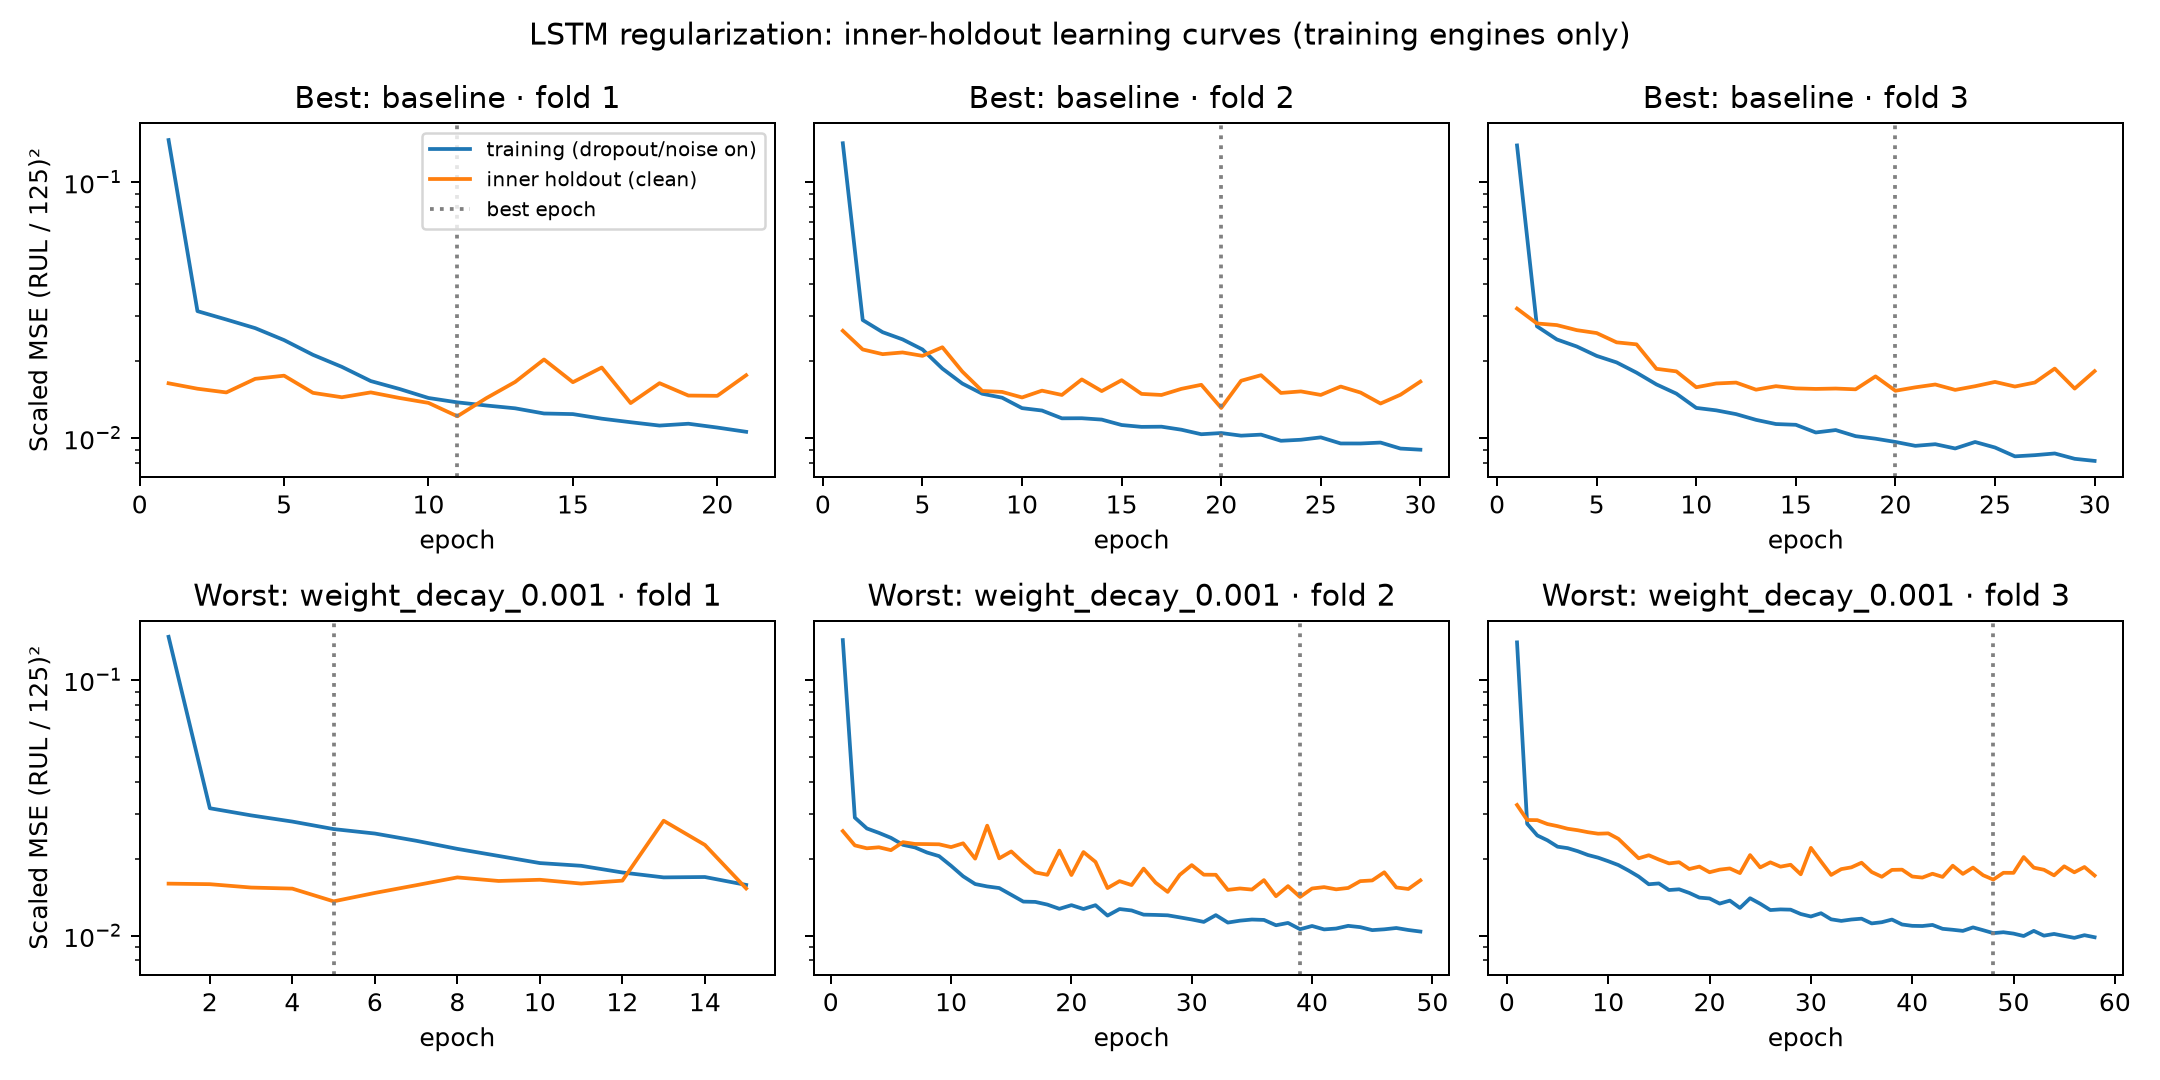

In [4]:
FIGURES.mkdir(parents=True, exist_ok=True)
figure = plot_regularization(records)
figure.savefig(FIGURES / "fd001_regularization.png", dpi=180)
plt.close(figure)
display(Image(filename=str(FIGURES / "fd001_regularization.png")))


## 4. Recommendation and evidence

Recommend the **best observed single-factor setting**, not a combination of
individually favorable settings that was never tested. For each factor, compare
its best alternative with the baseline. Fold differences are paired on identical
engines. One fixed training seed and a selected grid winner do not establish
statistical significance; small improvements need confirmation on additional
seeds and the final #55 rule before the model freeze. The official test must
not be used for those choices.


In [5]:
capped = {r["variant"]: r for r in records if r["target"] == "capped"}
chosen_name = table.iloc[0]["variant"]
chosen, baseline = capped[chosen_name], capped["baseline"]
paired_deltas = [a["scores"]["selection_rmse"] - b["scores"]["selection_rmse"]
                 for a, b in zip(chosen["folds"], baseline["folds"])]
factor_findings = {}
for factor in FACTORS:
    alternatives = table[table.variant.str.startswith(factor.split(".")[1] + "_")]
    best = alternatives.iloc[0]
    factor_findings[factor] = {"best_tested_alternative": best.variant,
                              "delta_from_baseline": float(best.delta_from_baseline)}
    print(f"{factor}: best alternative {best.variant}, capped delta {best.delta_from_baseline:+.3f}")
score = chosen["summary"]["selection_rmse"]
print(f"\nBest observed setting: {chosen_name}: {score['mean']:.3f} ± {score['std']:.3f}")
print("Paired fold deltas vs baseline:", [round(x, 3) for x in paired_deltas])
print("Resolved recommendation (no untested combination):")
print(json.dumps({k: chosen["config"][k] for k in ("model", "training", "inputs")}, indent=2))
print("PROVISIONAL: verify with the final #55 cap/selection rule and additional seeds before freeze.")


model.dropout: best alternative dropout_0.5, capped delta +0.985
training.weight_decay: best alternative weight_decay_0.0001, capped delta +0.048
training.input_noise_std: best alternative input_noise_std_0.01, capped delta +0.085
inputs.stride: best alternative stride_2, capped delta +1.691
training.patience: best alternative patience_20, capped delta +0.000

Best observed setting: baseline: 15.784 ± 0.440
Paired fold deltas vs baseline: [0.0, 0.0, 0.0]
Resolved recommendation (no untested combination):
{
  "model": {
    "type": "lstm",
    "hidden_size": 64,
    "num_layers": 1,
    "dropout": 0.3
  },
  "training": {
    "epochs": 100,
    "batch_size": 256,
    "learning_rate": 0.001,
    "weight_decay": 0.0,
    "grad_clip": 1.0,
    "scheduler": "cosine",
    "patience": 10,
    "loss": "mse",
    "device": "cpu",
    "seed": 42,
    "input_noise_std": 0.0
  },
  "inputs": {
    "type": "windows",
    "window": 30,
    "stride": 1,
    "n_regimes": 1,
    "include_cycle": false


## 5. Saved artifacts

One summary table, one learning-curve figure, a detailed JSON record and a gzip
CSV of every outer-held-out prediction. Each prediction carries the setting,
training target, engine, cycle, fold and true uncapped RUL. The JSON records
source/data hashes and package versions so stale results can be identified.
The existing LSTM settings remain the reference; this study records its
recommendation without changing other owners' notebooks or frozen settings.


In [6]:
prediction_name = "fd001_regularization_predictions.csv.gz"
predictions.to_csv(METRICS / prediction_name, index=False,
                   compression={"method": "gzip", "mtime": 0})
evidence = {
    "issue": 66, "subset": config["subset"],
    "selection_status": "provisional until #55: cap 125, true RUL <= 130",
    "protocol": {"folds": 3, "split_seed": 42, "training_seed": 42,
                 "official_test_used": False, "one_factor_at_a_time": True},
    "recommendation": {"variant": chosen_name, "config": chosen["config"],
                       "paired_fold_deltas": paired_deltas,
                       "factor_findings": factor_findings,
                       "status": "best observed; confirmation pending #55 and additional seeds"},
    "artifacts": {"table": "fd001_regularization.csv", "predictions": prediction_name,
                  "figure": "fd001_regularization.png",
                  "predictions_sha256": hashlib.sha256((METRICS / prediction_name).read_bytes()).hexdigest()},
    "runs": records,
}
(METRICS / "fd001_regularization.json").write_text(json.dumps(evidence, indent=2, allow_nan=False) + "\n")
print(f"Saved {len(records)} CV runs and {len(predictions):,} outer-held-out predictions.")
print(f"Total training time: {sum(r['seconds'] for r in records) / 60:.1f} minutes")


Saved 22 CV runs and 453,882 outer-held-out predictions.
Total training time: 14.8 minutes


## Observed findings

- The best observed capped setting was **baseline**, with selection RMSE
  **15.78 ± 0.44**, compared with
  **15.78 ± 0.44** for the tuned LSTM baseline
  (mean delta **+0.000 cycles**). This is a three-fold, seed-42 comparison.
- The resolved recommended config, paired fold differences and best alternative
  for each factor are printed above and saved in the JSON. Do not combine
  individually favorable settings without testing that combination.
- The ranking is **provisional** until #55 finalizes the training cap and
  selection rule. Predictions can be rescored for a changed threshold;
  a changed training cap needs new fits. Confirm promising changes over more
  training seeds before the freeze. No official test score is reported.

To reproduce from a fresh kernel after the project setup:

```bash
python -m jupyter nbconvert --execute --to notebook --inplace notebooks/phase2/10_regularization.ipynb
```

Matching per-run caches are reused; remove `results/models/studies/regularization/`
to repeat all 66 fits. The first run on a different source/environment rebuilds
the cache automatically.
